## Import Libraries

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

DATA = Path(r"E:\Northline")          # folder with the raw CSVs
CLEAN = DATA / "clean"
CLEAN.mkdir(exist_ok=True)

## Load the data

`events.csv` has 3.4M rows, so we set **dtypes** up front: repeated text columns become `category`, which cuts memory several-fold and speeds up group-bys.

In [89]:
cat = "category"

users = pd.read_csv(DATA / "users.csv", parse_dates=["first_seen_date"],
                    dtype={"region": cat, "primary_device": cat, "acquisition_channel": cat})

sessions = pd.read_csv(DATA / "sessions.csv", parse_dates=["session_start_ts", "session_date"],
                       dtype={"device": cat, "browser": cat, "channel": cat,
                              "landing_page_type": cat, "region": cat})

events = pd.read_csv(DATA / "events.csv", parse_dates=["event_ts"],
                     dtype={"event_name": cat, "page_type": cat, "item_id": "string",
                            "item_category": cat, "quantity": "Int64",
                            "shipping_tier": cat, "payment_type": cat, "order_id": "string"})

orders = pd.read_csv(DATA / "orders.csv", parse_dates=["order_ts"],
                     dtype={"promo_code": "string", "payment_method": cat,
                            "shipping_tier": cat, "order_status": cat})

order_items = pd.read_csv(DATA / "order_items.csv", dtype={"item_category": cat})
assignments = pd.read_csv(DATA / "experiment_assignments.csv", parse_dates=["exposure_ts"],
                          dtype={"variant": cat, "exposure_device": cat, "exposure_browser": cat})
products = pd.read_csv(DATA / "products.csv", dtype={"item_category": cat})

tables = {"users": users, "sessions": sessions, "events": events, "orders": orders,
          "order_items": order_items, "experiment_assignments": assignments, "products": products}

pd.DataFrame({
    "rows": {k: len(v) for k, v in tables.items()},
    "memory_MB": {k: v.memory_usage(deep=True).sum() / 1e6 for k, v in tables.items()},
})

,rows,memory_MB
users,240033,16.80
sessions,384037,53.00
events,3168603,"1,055.18"
orders,13339,4.08
order_items,25399,3.76
experiment_assignments,12249,1.58
products,720,0.15


In [90]:
events.head()

,event_id,event_ts,user_id,session_id,event_name,page_type,item_id,item_category,item_price,quantity,cart_value,shipping_tier,payment_type,purchase_revenue,order_id
0,E002806178,2025-10-28 18:08:38,U80339072,S00361971,session_start,product,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>
1,E000893670,2025-11-28 05:50:21,U49510779,S00115267,add_payment_info,checkout,<NA>,NaN,NaN,<NA>,88.00,NaN,paypal,NaN,<NA>
2,E002626044,2025-11-24 13:17:47,U66426520,S00338837,page_view,product,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>
3,E001787449,2025-12-17 21:17:18,U94242288,S00230754,page_view,product,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>
4,E001538167,2025-12-14 06:09:06,U80582680,S00198628,page_view,product,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>


# 1. Data Quality & Cleaning — Northline E-commerce

## Duplicate primary keys — every count should be 0

In [91]:
keys = {"users": "user_id", "sessions": "session_id", "events": "event_id",
        "orders": "order_id", "products": "item_id", "experiment_assignments": "user_id"}

pd.Series({t: tables[t][k].duplicated().sum() for t, k in keys.items()}, name="duplicate_keys")

users                     0
sessions                  0
events                    0
orders                    0
products                  0
experiment_assignments    0
Name: duplicate_keys, dtype: int64

## Orphan records — child rows whose parent key doesn't exist

In [92]:
orphans = {
    "sessions -> users":       (~sessions.user_id.isin(users.user_id)).sum(),
    "events -> sessions":      (~events.session_id.isin(sessions.session_id)).sum(),
    "orders -> sessions":      (~orders.session_id.isin(sessions.session_id)).sum(),
    "order_items -> orders":   (~order_items.order_id.isin(orders.order_id)).sum(),
    "order_items -> products": (~order_items.item_id.isin(products.item_id)).sum(),
}
pd.Series(orphans, name="orphans")

sessions -> users          0
events -> sessions         0
orders -> sessions         0
order_items -> orders      0
order_items -> products    0
Name: orphans, dtype: int64

## Test / internal orders

Look at every promo code: a real promo has normal order values. Anything with $0 revenue is suspicious.

In [93]:
(orders.assign(promo_code=orders.promo_code.fillna("(none)"))
       .groupby("promo_code")
       .agg(orders=("order_id", "size"),
            avg_revenue=("order_revenue", "mean"),
            min_revenue=("order_revenue", "min"))
       .sort_values("orders", ascending=False))

,orders,avg_revenue,min_revenue
promo_code,,,
HOLIDAY,3899,134.21,6.82
(none),3490,141.42,7.24
BLACKFRIDAY,1436,106.26,5.78
AFTERXMAS,1202,105.72,5.78
EARLYBF,944,117.51,6.85
CYBERWEEK,904,118.81,10.44
CYBER40,670,105.16,9.62
FAMILY25,549,118.97,9.35
VETS20,108,125.76,16.49


In [94]:
zero = orders[orders.order_revenue == 0]
zero.groupby(["user_id", "promo_code"]).agg(orders=("order_id", "size"),
                                            revenue=("order_revenue", "sum"))

,,orders,revenue
user_id,promo_code,,
U54072979,QA-TEST100,13,0.00
U80051684,QA-TEST100,12,0.00
U80615564,QA-TEST100,13,0.00


In [95]:
qa_users = set(orders.loc[orders.promo_code == "QA-TEST100", "user_id"])
print(f"Internal QA accounts: {len(qa_users)} users, "
      f"{(orders.promo_code == 'QA-TEST100').sum()} orders at $0")

Internal QA accounts: 3 users, 38 orders at $0


## Duplicate purchase events — same `order_id` logged more than once

In [96]:
purch = events[events.event_name == "purchase"]
dup_counts = purch.order_id.value_counts()
dups = dup_counts[dup_counts > 1]

print(f"order_ids logged more than once: {len(dups)}")
print(f"extra purchase rows: {(dups - 1).sum()}")
print(f"revenue inflated by: ${purch[purch.order_id.duplicated()].purchase_revenue.sum():,.2f}")

order_ids logged more than once: 102
extra purchase rows: 102
revenue inflated by: $13,230.79


In [97]:
# What a duplicate looks like: seconds apart -> confirmation-page refresh
(purch[purch.order_id.isin(dups.index[:3])]
      .sort_values(["order_id", "event_ts"])
      [["order_id", "event_id", "event_ts", "purchase_revenue"]])

,order_id,event_id,event_ts,purchase_revenue
721473,NL5011937,E000900771,2025-12-03 17:40:12,87.09
2352743,NL5011937,E000900772,2025-12-03 17:40:15,87.09
2700070,NL5021812,E001633183,2025-12-28 15:42:14,64.03
1446644,NL5021812,E001633184,2025-12-28 15:42:22,64.03
2389794,NL5028287,E002113407,2025-12-04 11:11:19,17.43
990170,NL5028287,E002113408,2025-12-04 11:11:26,17.43


## Reconcile — purchase events (deduplicated) vs. the orders table

In [98]:
purch_dedup = purch.sort_values("event_ts").drop_duplicates("order_id")

pd.DataFrame({
    "count":   [len(purch), len(purch_dedup), len(orders)],
    "revenue": [purch.purchase_revenue.sum(), purch_dedup.purchase_revenue.sum(),
                orders.order_revenue.sum()],
}, index=["purchase events (raw)", "purchase events (dedup)", "orders table"])

,count,revenue
purchase events (raw),13441,"1,689,592.87"
purchase events (dedup),13339,"1,676,362.08"
orders table,13339,"1,676,362.08"


In [99]:
ev_ids, ord_ids = set(purch.order_id), set(orders.order_id)
print("in events, not in orders:", len(ev_ids - ord_ids))
print("in orders, not in events:", len(ord_ids - ev_ids))

in events, not in orders: 0
in orders, not in events: 0


## Bot / non-human traffic

Real shoppers view a handful of pages per session. Look for a break in the distribution, then profile who is past it.

In [100]:
pv = (events[events.event_name == "page_view"]
      .groupby("session_id", observed=True).size().rename("page_views"))

pv.describe(percentiles=[.5, .9, .99, .999]).round(1)

count   384,037.00
mean          4.80
std           6.50
min           1.00
50%           4.00
90%           9.00
99%          15.00
99.9%       120.00
max         149.00
Name: page_views, dtype: float64

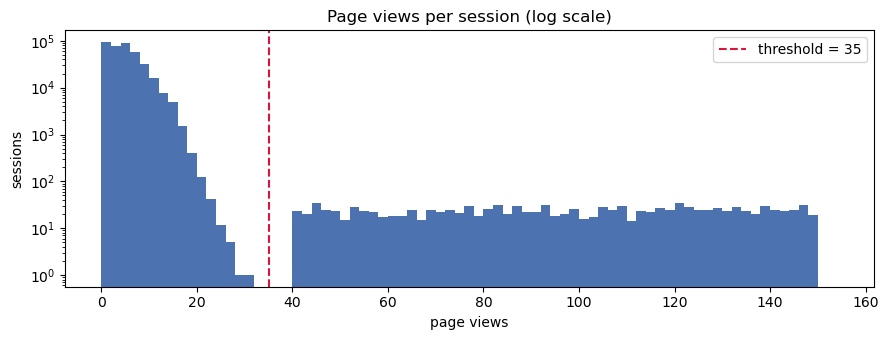

In [101]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(pv, bins=range(0, 155, 2), color="#4C72B0")
ax.set_yscale("log")
ax.axvline(35, color="crimson", ls="--", label="threshold = 35")
ax.set(title="Page views per session (log scale)", xlabel="page views", ylabel="sessions")
ax.legend(); plt.tight_layout(); plt.show()

In [102]:
heavy_sessions = pv[pv > 35].index
heavy_users = sessions.loc[sessions.session_id.isin(heavy_sessions), "user_id"].unique()

s_heavy = sessions[sessions.user_id.isin(heavy_users)]
atc_users = set(events.loc[events.event_name == "add_to_cart", "user_id"])

profile = (s_heavy.assign(night=s_heavy.session_start_ts.dt.hour.between(2, 5))
           .groupby("user_id")
           .agg(sessions=("session_id", "size"),
                devices=("device", lambda x: ",".join(sorted(set(x)))),
                browsers=("browser", lambda x: ",".join(sorted(set(x)))),
                channels=("channel", lambda x: ",".join(sorted(set(x)))),
                sessions_2_to_5am=("night", "sum")))
profile["max_pv_per_session"] = s_heavy.assign(pv=s_heavy.session_id.map(pv)).groupby("user_id").pv.max()
profile["added_to_cart"] = profile.index.isin(atc_users)
profile["orders"] = profile.index.map(orders.user_id.value_counts()).fillna(0).astype(int)
profile.sort_values("sessions", ascending=False)

,sessions,devices,browsers,channels,sessions_2_to_5am,max_pv_per_session,added_to_cart,orders
user_id,,,,,,,,
U91813446,67,desktop,Chrome,direct,10,148,False,0
U44645909,65,desktop,Chrome,direct,11,145,False,0
U11987780,64,desktop,Chrome,direct,10,147,False,0
U46390686,63,desktop,Chrome,direct,12,148,False,0
U74281764,62,desktop,Chrome,direct,5,147,False,0
U23463145,62,desktop,Chrome,direct,9,147,False,0
U11880009,60,desktop,Chrome,direct,9,146,False,0
U54398942,60,desktop,Chrome,direct,5,148,False,0
U24498091,58,desktop,Chrome,direct,8,148,False,0


In [103]:
# Speed check: median seconds between consecutive events, heavy vs. normal sessions
ev_sorted = events[["session_id", "event_ts"]].sort_values(["session_id", "event_ts"])
gap = ev_sorted.groupby("session_id", observed=True).event_ts.diff().dt.total_seconds()
is_heavy = ev_sorted.session_id.isin(heavy_sessions)

pd.Series({"heavy (>35 pv)": gap[is_heavy].median(),
           "normal": gap[~is_heavy].median()}, name="median_seconds_between_events")

heavy (>35 pv)    1.00
normal           19.00
Name: median_seconds_between_events, dtype: float64

**Bot rule:** a user is a bot if any session has **> 35 page views** AND they **never added to cart**.

Evidence: all flagged users are desktop / Chrome / direct, browse at 2–5 am, move ~1 second per event (vs. ~19 s for people), and never add to cart or buy.

In [104]:
bot_users = set(u for u in heavy_users if u not in atc_users)
print(f"bot users: {len(bot_users)}")
print(f"bot sessions: {sessions.user_id.isin(bot_users).sum():,}")
print(f"bot events: {events.user_id.isin(bot_users).sum():,}")

bot users: 30
bot sessions: 1,307
bot events: 201,677


## Nulls, ranges and the year boundary

In [105]:
pd.Series({
    "events: null event_name": events.event_name.isna().sum(),
    "view_item: null item_category": events.loc[events.event_name == "view_item", "item_category"].isna().sum(),
    "view_item: null item_id": events.loc[events.event_name == "view_item", "item_id"].isna().sum(),
    "purchase: null order_id": purch.order_id.isna().sum(),
    "events: price <= 0": (events.item_price <= 0).sum(),
    "orders: negative amounts": ((orders[["subtotal", "discount", "order_revenue"]] < 0).any(axis=1)).sum(),
    "orders: discount > subtotal": (orders.discount > orders.subtotal).sum(),
    "orders: revenue math breaks": ((orders.order_revenue - (orders.subtotal - orders.discount
                                     + orders.shipping_fee + orders.tax)).abs() > 0.02).sum(),
}, name="count")

events: null event_name             0
view_item: null item_category    3590
view_item: null item_id             0
purchase: null order_id             0
events: price <= 0                  0
orders: negative amounts            0
orders: discount > subtotal         0
orders: revenue math breaks         0
Name: count, dtype: int64

In [106]:
sessions.channel.value_counts(normalize=True).mul(100).round(2).rename("% of sessions")

channel
organic_search   32.61
paid_search      21.74
direct           15.49
social           12.42
email             9.45
affiliate         6.35
(not set)         1.94
Name: % of sessions, dtype: float64

In [107]:
pd.DataFrame({
    "min": [events.event_ts.min(), sessions.session_start_ts.min(), orders.order_ts.min(), assignments.exposure_ts.min()],
    "max": [events.event_ts.max(), sessions.session_start_ts.max(), orders.order_ts.max(), assignments.exposure_ts.max()],
}, index=["events", "sessions", "orders", "experiment"])

,min,max
events,2025-10-01 00:01:13,2026-01-01 00:12:33
sessions,2025-10-01 00:01:13,2025-12-31 23:59:40
orders,2025-10-01 01:03:32,2026-01-01 00:06:33
experiment,2025-11-03 00:14:03,2025-12-21 23:57:08


In [108]:
# Orders that spill past midnight on Dec 31
(orders[orders.order_ts >= "2026-01-01"]
       .merge(sessions[["session_id", "session_start_ts"]], on="session_id")
       [["order_id", "session_start_ts", "order_ts", "order_revenue"]])

,order_id,session_start_ts,order_ts,order_revenue
0,NL5030517,2025-12-31 23:58:17,2026-01-01 00:06:33,82.38


## Revenue rule — status mix, gross vs. net

In [109]:
real = orders[orders.promo_code.fillna("") != "QA-TEST100"]
status = (real.groupby("order_status", observed=True)
              .agg(orders=("order_id", "size"),
                   gross_revenue=("order_revenue", "sum"),
                   returned_amount=("returned_amount", "sum")))
status["pct_orders"] = status.orders / status.orders.sum() * 100
status.sort_values("orders", ascending=False)

,orders,gross_revenue,returned_amount,pct_orders
order_status,,,,
completed,9260,"1,054,400.85",0.00,69.62
partially_returned,2646,"497,182.47","178,707.54",19.89
returned,1145,"91,746.75","80,848.36",8.61
cancelled,250,"33,032.01",0.00,1.88


In [110]:
gross = real.order_revenue.sum()
net = real.loc[real.order_status != "cancelled", "order_revenue"].sum() - real.returned_amount.sum()
print(f"Gross revenue: ${gross:,.0f}")
print(f"Net revenue:   ${net:,.0f}  ({net / gross:.1%} of gross)")

Gross revenue: $1,676,362
Net revenue:   $1,383,774  (82.5% of gross)


## Build and save the clean tables

In [111]:
excluded_users = bot_users | qa_users

clean_sessions = sessions[~sessions.user_id.isin(excluded_users)].copy()

clean_events = events[events.session_id.isin(clean_sessions.session_id)].copy()
# keep the first purchase event per order
is_purchase = clean_events.event_name == "purchase"
dup_purchase = is_purchase & clean_events.sort_values("event_ts").duplicated("order_id").reindex(clean_events.index)
clean_events = clean_events[~dup_purchase]
# fill missing item_category from the catalog
cat_map = products.set_index("item_id").item_category
clean_events["item_category"] = clean_events.item_category.fillna(
    clean_events.item_id.map(cat_map).astype(clean_events.item_category.dtype))

clean_orders = orders[~orders.user_id.isin(excluded_users)].copy()
clean_orders["is_cancelled"] = clean_orders.order_status == "cancelled"
clean_orders["net_revenue"] = np.where(clean_orders.is_cancelled, 0,
                                       clean_orders.order_revenue - clean_orders.returned_amount)

clean_order_items = order_items[order_items.order_id.isin(clean_orders.order_id)].copy()
clean_users = users[~users.user_id.isin(excluded_users)].copy()
clean_assignments = assignments[~assignments.user_id.isin(excluded_users)].copy()

In [112]:
pd.DataFrame({
    "raw": [len(sessions), len(events), len(orders), len(order_items), len(users)],
    "clean": [len(clean_sessions), len(clean_events), len(clean_orders), len(clean_order_items), len(clean_users)],
}, index=["sessions", "events", "orders", "order_items", "users"]).assign(removed=lambda d: d.raw - d.clean)

,raw,clean,removed
sessions,384037,382692,1345
events,3168603,2966520,202083
orders,13339,13301,38
order_items,25399,25361,38
users,240033,240000,33


In [113]:
# Final reconciliation on clean data: must match exactly
cp = clean_events[clean_events.event_name == "purchase"]
assert len(cp) == len(clean_orders)
assert abs(cp.purchase_revenue.sum() - clean_orders.order_revenue.sum()) < 0.01
assert clean_events.loc[clean_events.event_name == "view_item", "item_category"].isna().sum() == 0
print(f"Reconciled: {len(cp):,} orders, ${cp.purchase_revenue.sum():,.2f} gross revenue")

Reconciled: 13,301 orders, $1,676,362.08 gross revenue


In [114]:
for name, df in {"users": clean_users, "sessions": clean_sessions, "events": clean_events,
                 "orders": clean_orders, "order_items": clean_order_items,
                 "experiment_assignments": clean_assignments, "products": products}.items():
    df.to_parquet(CLEAN / f"{name}.parquet", index=False)

sorted(p.name for p in CLEAN.glob("*.parquet"))

['events.parquet',
 'experiment_assignments.parquet',
 'order_items.parquet',
 'orders.parquet',
 'products.parquet',
 'sessions.parquet',
 'users.parquet']